## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Marilyn Ross

**Date:** 10/6

Q1.1
Q1.2


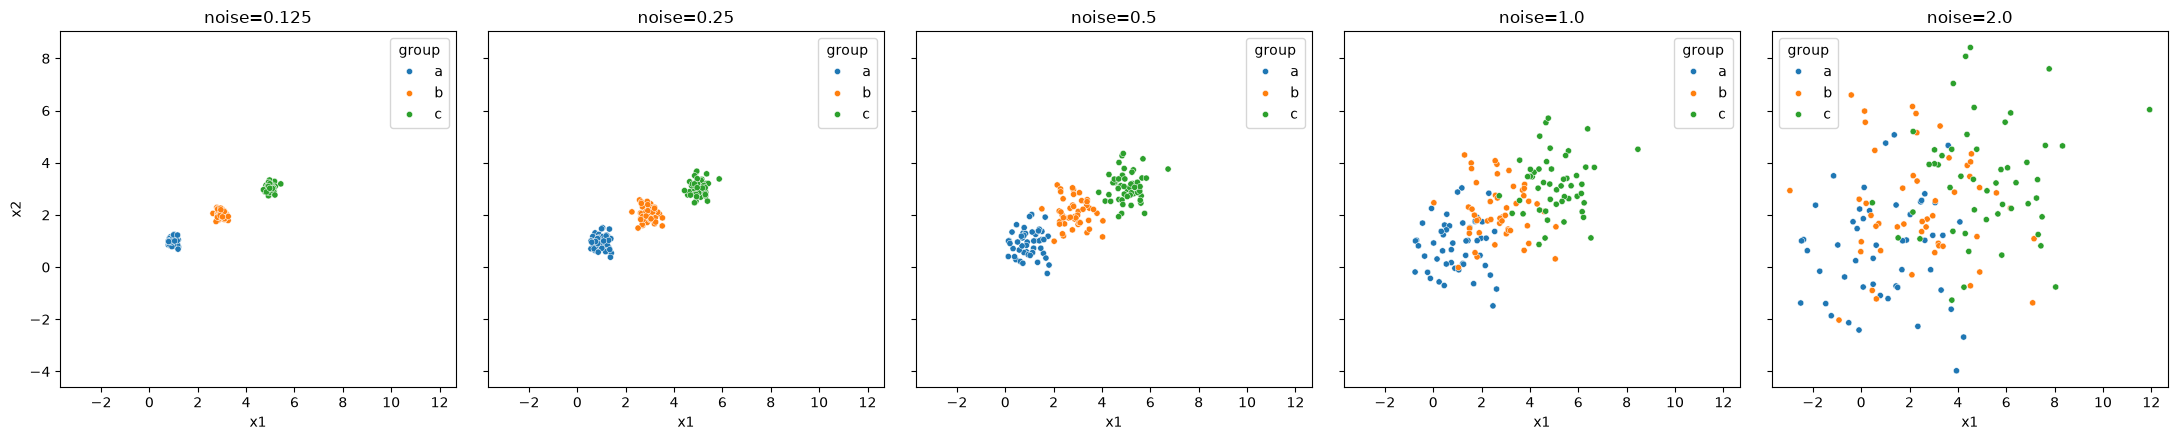

Analysis: As noise increases, the clusters blur together. At 0.125 and 0.25 they are clearly separate, at 0.5 they start to touch, and at 1.0 and 2.0 they overlap into one cloud.
Q1.3


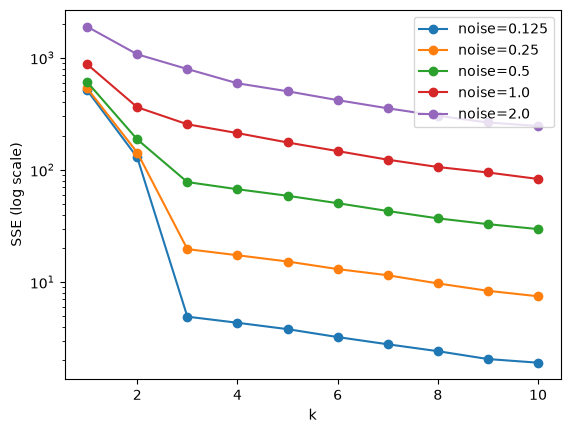

Analysis: More noise raises the whole curve. For noise up to 0.5 there is a sharp elbow at k=3, so picking k is easy. At 1.0 the elbow is weak, and at 2.0 there is none, so no k stands out.
Q1.4
SSE drops sharply while new clusters split real groups (k=1 to 3, since the data has 3 centers). After that, extra clusters only split noise, so the curve flattens; that bend is the elbow. With high noise the groups overlap, so there is no big drop and no elbow.


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

print("Q1.1")
def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

print("Q1.2")
datasets = {'0.125':df0_125,'0.25':df0_25,'0.5':df0_5,'1.0':df1_0,'2.0':df2_0}
fig, axes = plt.subplots(1,5,figsize=(22,4.5),sharex=True,sharey=True)
for ax,(n,df) in zip(axes,datasets.items()):
    sns.scatterplot(data=df,x='x1',y='x2',hue='group',ax=ax,s=20); ax.set_title(f'noise={n}')
plt.tight_layout(); plt.show()
print("Analysis: As noise increases, the clusters blur together. At 0.125 and 0.25 they are clearly separate, "
      "at 0.5 they start to touch, and at 1.0 and 2.0 they overlap into one cloud.")

print("Q1.3")
for n, df in datasets.items():
    sse = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(df[['x1','x2']]).inertia_ for k in range(1, 11)]
    plt.plot(range(1, 11), sse, marker='o', label=f'noise={n}')
plt.yscale('log'); plt.xlabel('k'); plt.ylabel('SSE (log scale)'); plt.legend(loc='upper right'); plt.show()
print("Analysis: More noise raises the whole curve. For noise up to 0.5 there is a sharp elbow at k=3, "
      "so picking k is easy. At 1.0 the elbow is weak, and at 2.0 there is none, so no k stands out.")

print("Q1.4")
print("SSE drops sharply while new clusters split real groups (k=1 to 3, since the data has 3 centers). "
      "After that, extra clusters only split noise, so the curve flattens; that bend is the elbow. "
      "With high noise the groups overlap, so there is no big drop and no elbow.")

Q2.1
(148, 6)
Year                                int64
Country                               str
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object
Analysis: All variables are numeric, so no conversion is needed. Drop the leftover 'index' column. Spending is very skewed (US = $778B vs median ~$1B), so plots use an arcsinh scale.
Q2.2


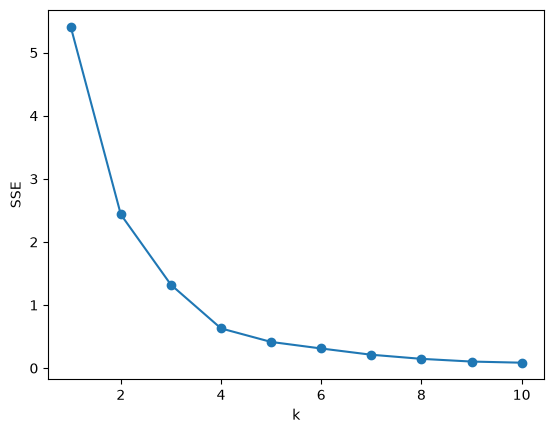

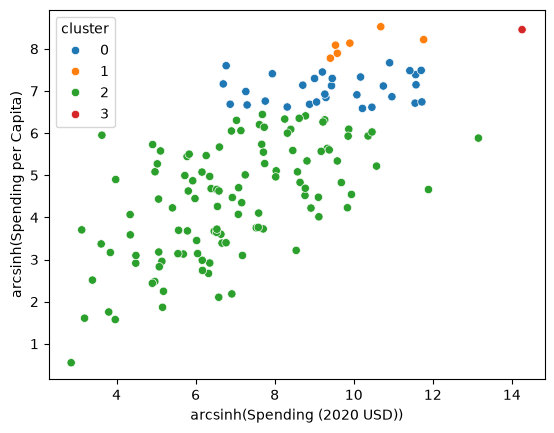

        Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      30.0   17077.591354  20583.053357     405.790494   
1                       6.0   19443.362047  22861.507114    6095.708713   
2                     111.0    4859.185065  25405.739131       8.622460   
3                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          2294.039665    5857.060906   26296.001003   61712.537169   
1          7023.251766    8624.225729   18857.070183   64558.400000   
2           130.010211     382.464677    2297.032353  257973.429834   
3        778397.200000  778397.200000  778397.20

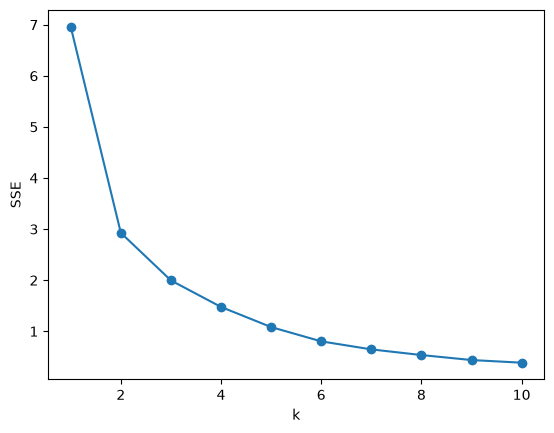

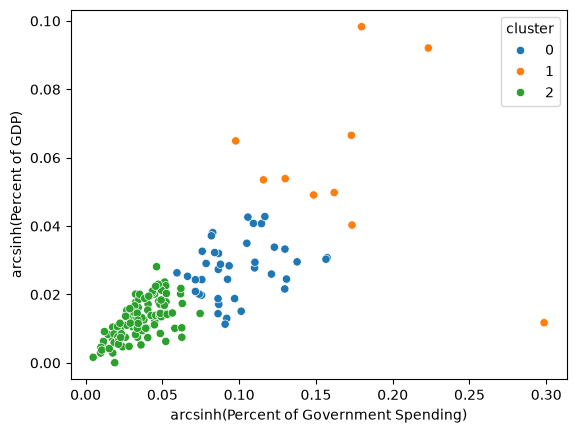

        Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                 39.0  0.098683  0.024125  0.059520   
1                                 10.0  0.171289  0.058725  0.097882   
2                                 99.0  0.035777  0.014549  0.004896   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1        0.135010  0.168248  0.179081  0.303027           10.0  0.058071   
2        0.025921  0.034261  0.047402  0.074624           99.0  0.012664   

                                                                     
              std       min       25%   

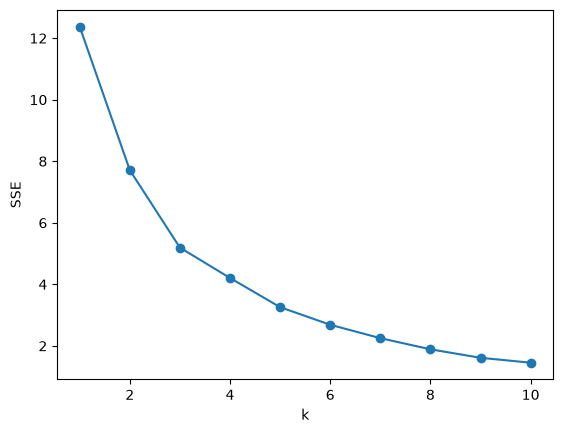

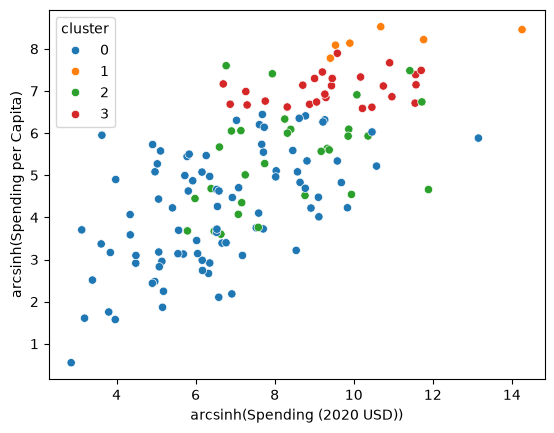

        Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                      86.0    4513.543790   27841.230783     8.622460   
1                       6.0  147964.582042  309635.189564  6095.708713   
2                      30.0    9073.543709   18135.032885   163.926877   
3                      26.0   15330.618681   18923.469359   405.790494   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0          81.022976    288.061512   1138.618231  257973.429834   
1        7700.424616  15897.570598  53872.942442  778397.200000   
2         522.737081   1663.090134   8646.648849   72937.064048   
3        3176.345598   5857.060906  21818.934764   60675.039625   

        Spe

In [5]:
#Study 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

print("Q2.1")
df = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')
df = df[df['Year'] == 2020].dropna().drop(columns='index').copy()
print(df.shape, df.dtypes, sep='\n')
print("Analysis: All variables are numeric, so no conversion is needed. Drop the leftover 'index' column. "
      "Spending is very skewed (US = $778B vs median ~$1B), so plots use an arcsinh scale.")

def cluster(cols, k=None):
    X = (df[cols] - df[cols].min()) / (df[cols].max() - df[cols].min())
    if k is None:
        sse = [KMeans(n_clusters=i, n_init=10, random_state=0).fit(X).inertia_ for i in range(1, 11)]
        plt.plot(range(1, 11), sse, marker='o'); plt.xlabel('k'); plt.ylabel('SSE'); plt.show()
        return
    df['cluster'] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)
    sns.scatterplot(x=np.arcsinh(df[cols[0]]), y=np.arcsinh(df[cols[1]]), hue=df['cluster'], palette='tab10')
    plt.xlabel(f'arcsinh({cols[0]})'); plt.ylabel(f'arcsinh({cols[1]})'); plt.show()
    print(df.groupby('cluster')[cols].describe())
    print(df.loc[df['Country'] == 'United States of America', ['Country', 'cluster']])

cols2 = ['Spending (2020 USD)', 'Spending per Capita']
cols3 = ['Percent of Government Spending', 'Percent of GDP']
cols4 = cols2 + cols3

print("Q2.2")
cluster(cols2)
cluster(cols2, k=4)
print("Analysis: Elbow at k=4. The US is alone in its own cluster. The rest split by spending per capita: "
      "small rich states (Saudi Arabia, Israel, Norway), Western countries, and everyone else. The pattern is mostly wealth.")

print("Q2.3")
cluster(cols3)
cluster(cols3, k=3)
print("Analysis: Elbow at k=3. Clusters now reflect military burden, not size, so rich and poor countries mix. "
      "The US is in the medium-burden group with countries like Iran and Chad.")

print("Q2.4")
cluster(cols4)
cluster(cols4, k=4)
print("Analysis: No clear elbow; k=4. The US joins Saudi Arabia, Israel, Singapore, Kuwait and Oman as high spenders on both scales. "
      "The clusters combine the wealth and burden patterns from parts 2 and 3.")

print("Q2.5")
print("Analysis: Somewhat. It separated countries by wealth and by burden, but results are driven by the US outlier "
      "and mostly confirm what we already knew.")

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]